In [1]:
import sys
sys.path.append("..")   # so we can import from src/

import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from src.text_utils import clean_text

df = pd.read_csv("../data/spam.csv", encoding="latin-1")[["v1", "v2"]]
df.columns = ["label", "message"]
df = df.drop_duplicates().reset_index(drop=True)
df["target"] = df["label"].map({"ham": 0, "spam": 1})

# This time we split the RAW messages. Cleaning now happens inside the pipeline.
X_train, X_test, y_train, y_test = train_test_split(
    df["message"], df["target"], test_size=0.2, random_state=42, stratify=df["target"]
)

In [2]:
# Compare three models, each wrapped in a Pipeline (TF-IDF + classifier)
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

pipelines, results = {}, []
for name, clf in models.items():
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(preprocessor=clean_text, stop_words="english")),
        ("clf", clf),
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    pipelines[name] = pipe
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

results_df = pd.DataFrame(results).round(4)
print("Always-ham baseline accuracy:", round(1 - y_test.mean(), 4))
print(results_df)

Always-ham baseline accuracy: 0.8733
                 Model  Accuracy  Precision  Recall      F1
0          Naive Bayes    0.9662     0.9898  0.7405  0.8472
1  Logistic Regression    0.9603     0.9891  0.6947  0.8161
2        Random Forest    0.9758     0.9818  0.8244  0.8963


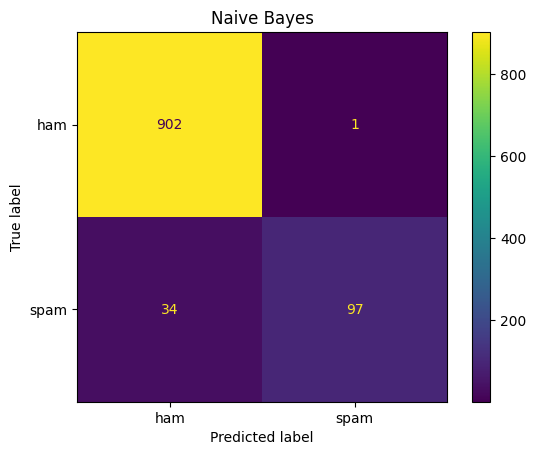

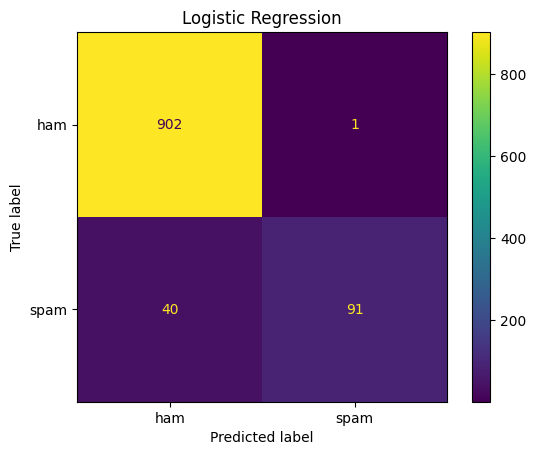

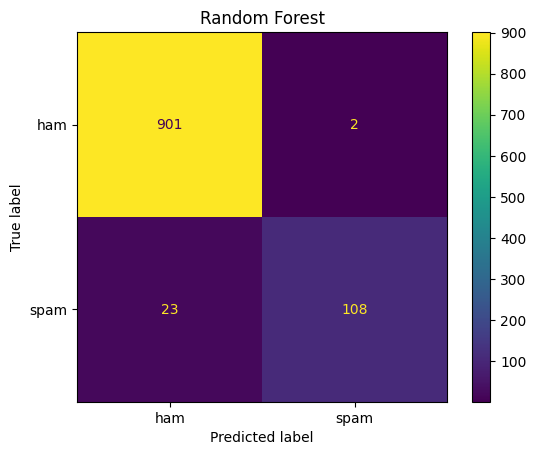

Best model: Random Forest
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       0.98      0.82      0.90       131

    accuracy                           0.98      1034
   macro avg       0.98      0.91      0.94      1034
weighted avg       0.98      0.98      0.97      1034



In [3]:
# Confusion matrix for each model
for name, pipe in pipelines.items():
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot()
    plt.title(name)
    plt.show()

# Detailed report for the best model by F1
best_name = results_df.sort_values("F1", ascending=False).iloc[0]["Model"]
print("Best model:", best_name)
print(classification_report(y_test, pipelines[best_name].predict(X_test), target_names=["ham", "spam"]))

In [4]:
# Cross-validation: a more reliable score than one single split
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, df["message"], df["target"], cv=5, scoring="f1")
    print(f"{name}: mean F1 = {scores.mean():.4f} (+/- {scores.std():.4f})")

Naive Bayes: mean F1 = 0.8303 (+/- 0.0255)
Logistic Regression: mean F1 = 0.8088 (+/- 0.0335)
Random Forest: mean F1 = 0.8758 (+/- 0.0195)


In [5]:
# Save the best model
os.makedirs("../models", exist_ok=True)
joblib.dump(pipelines[best_name], "../models/spam_model.joblib")

# Check it loads and works on raw text
loaded = joblib.load("../models/spam_model.joblib")
print(loaded.predict(["Congratulations! You have won a free prize, call now to claim",
                      "Hey, are we meeting for lunch tomorrow?"]))

[1 0]
